# Business KPIs #
Material for the report section *Business Evaluation, Value and Recommendations*. Compares the business value of the
*same hour last week* baseline with XGBoost (`xgboost.ipynb`), the CNN (`neural_network.ipynb`), the LSTM (`lstm.ipynb`)
and the local heads (`local_vs_global.ipynb`) on their saved test forecasts. These are the same 10,495 hours,
20 Jan - 3 Apr 2023, so nothing is retrained here.

* **Imbalance**: each value is the mean power over one hour in MW, so the absolute error of one hour is the imbalance in
  MWh (`\cref{sec:imbalance}`). The total imbalance $I$ and its reduction $\Delta I$ against the baseline are eq. imbalance and eq. reduction.
* **Thresholds** are in % of the hour's actual consumption, so areas of different size (Oslo is about 6 times Tromsø) are
  comparable. They are set in the cell below.
* **Peak hours** are the top `PEAK_QUANTILE` of actual consumption within each area. Errors there are assumed to cost more.
* **Imbalance cost** uses the real single imbalance prices of the test period from the eSett open data API (EXP14). This
  is done per hour and price area, relative to a perfect forecast; imbalance fees and intraday trading are left out.

In [1]:
import json
import sys
import urllib.request
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "../machine_learning")
from forecast_checks import DATA_DIR, ForecastValidator, MakeTrainingData, paired_bootstrap, save_tables

#Thresholds in % of the hour's actual consumption
LARGE_ERROR_PCT = 10          #|error| above this is a large error
TOLERANCE_PCT = 5             #|error| at or below this is within tolerance
DAILY_LARGE_PCT = 5           #a day whose imbalance is above this % of its consumption is a bad day
PEAK_QUANTILE = 0.90          #peak hours: the top 10 % of consumption within each area
TAIL_SHARE = 0.01             #the most expensive 1 % of hours, for how concentrated the cost is
THRESHOLD_CURVE = np.arange(0, 31)   #thresholds [%] for the exceedance curve

ML_RESULTS = Path("../machine_learning/results")
RESULTS, FIGURES = Path("results"), Path("figures")
RESULTS.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)
PRICES_CSV = DATA_DIR / "esett_prices.csv"
BASELINE = "Same hour last week"
MODELS = {"XGBoost": "xgboost", "CNN": "neural_network", "LSTM": "lstm", "Local heads": "local_vs_global"}
SAVED_AS = {"CNN": "Neural network"}   #name neural_network.ipynb saved the forecast under
AREAS = {"oslo": "NO1 Oslo", "stavanger": "NO2 Stavanger", "trondheim": "NO3 Trondheim", "tromsø": "NO4 Tromsø",
         "bergen": "NO5 Bergen", "helsingfors": "FI Helsingfors"}
#eSett market balance area (EIC code) of each price area
MBAS = {"NO1 Oslo": "10YNO_1________2", "NO2 Stavanger": "10YNO_2________T", "NO3 Trondheim": "10YNO_3________J",
        "NO4 Tromsø": "10YNO_4________9", "NO5 Bergen": "10Y1001A1001A48H", "FI Helsingfors": "10YFI_1________U"}

## Forecasts and prices ##
The saved test forecasts of every model in one validator (`add` checks that they cover the same hours). "Global CNN" in
`local_vs_global_predictions.json` is the same forecast as the CNN, so only the local heads are taken from there.

In [2]:
test = ForecastValidator.load_predictions(ML_RESULTS / "xgboost_predictions.json")
for name, stem in MODELS.items():
    if name not in test.forecasts:
        test.add(name, ForecastValidator.load_predictions(ML_RESULTS / f"{stem}_predictions.json").forecasts[SAVED_AS.get(name, name)])
test.groups = test.groups.map(AREAS).rename("Price area")
NAMES = list(test.forecasts)          #baseline first
df = MakeTrainingData().df
info = df.loc[test.actual.index]
assert (info["location"].astype(str).map(AREAS) == test.groups).all()
assert (test.actual > 0).all(), "Errors in % of consumption need consumption above 0"
print(f"{len(info)} test hours, {info['date'].min().date()} - {info['date'].max().date()}; models {NAMES}")

10495 test hours, 2023-01-20 - 2023-04-03; models ['Same hour last week', 'XGBoost', 'CNN', 'LSTM', 'Local heads']


Single imbalance prices from eSett (EXP14), fetched once and cached in `data/esett_prices.csv`; delete the file to fetch again.
Under the single-price model the imbalance purchase and sales prices are equal. `spread` = imbalance price − day-ahead
spot price, and `system_direction` is the main direction of regulation: 1 = up-regulation (the system is short),
−1 = down-regulation (the system is long), 0 = none.

In [3]:
def fetch_prices(start: pd.Timestamp, end: pd.Timestamp) -> pd.DataFrame:
    #One request per area covers the whole test period
    frames = []
    for area, mba in MBAS.items():
        url = (f"https://api.opendata.esett.com/EXP14/Prices?start={start:%Y-%m-%dT%H:%M:%S}.000Z"
               f"&end={end:%Y-%m-%dT%H:%M:%S}.000Z&mba={mba}")
        with urllib.request.urlopen(url, timeout=60) as response:
            frames.append(pd.DataFrame(json.load(response)).assign(area=area))
    return pd.concat(frames, ignore_index=True)[["timestampUTC", "area", "imblSalesPrice", "imblSpotDifferencePrice",
                                                 "mainDirRegPowerPerMBA"]]


if not PRICES_CSV.exists():
    padding = pd.Timedelta(days=1)
    fetch_prices(info["time"].min().floor("D") - padding, info["time"].max().ceil("D") + padding).to_csv(PRICES_CSV, index=False)
prices = pd.read_csv(PRICES_CSV).rename(columns={"timestampUTC": "time", "imblSalesPrice": "imbalance_price",
                                                  "imblSpotDifferencePrice": "spread",
                                                  "mainDirRegPowerPerMBA": "system_direction"})
prices["time"] = pd.to_datetime(prices["time"], utc=True).astype(info["time"].dtype)

#One row per test hour and area; the forecasts are added per model below
hours = pd.DataFrame({"area": test.groups, "time": info["time"], "date": info["date"], "actual": test.actual})
hours = hours.merge(prices, on=["time", "area"], how="left", validate="one_to_one").set_index(test.actual.index)
assert hours[["imbalance_price", "spread", "system_direction"]].notna().all().all(), "Hours without an eSett price"
hours["peak"] = hours["actual"] >= hours.groupby("area")["actual"].transform("quantile", PEAK_QUANTILE)
hours.groupby("area")[["imbalance_price", "spread"]].describe().T.round(1)

area                   FI Helsingfors  NO1 Oslo  NO2 Stavanger  NO3 Trondheim  \
imbalance_price count          1750.0    1749.0         1749.0         1749.0   
                mean             78.3     103.4          104.2           45.9   
                std             120.2      44.2           44.0           29.7   
                min            -200.0     -10.0          -10.0           -2.6   
                25%              25.6      82.5           85.0           24.3   
                50%              63.0      97.0           98.3           39.3   
                75%             107.8     114.0          115.0           60.0   
                max            3000.0     700.0          700.0          178.1   
spread          count          1750.0    1749.0         1749.0         1749.0   
                mean              2.1      -3.3           -2.5           -4.8   
                std             112.3      31.9           31.6           19.6   
                min            -205.0     -96.2          -96.2         -156.5   
                25%             -20.5     -16.1          -15.0          -15.5   
                50%               0.0       0.0            0.0            0.0   
                75%               1.8       0.0            0.0            0.0   
                max            2865.1     487.6          487.6           81.2   

area                   NO4 Tromsø  NO5 Bergen  
imbalance_price count      1749.0      1749.0  
                mean         34.2       102.5  
                std          24.6        43.4  
                min         -10.0       -10.0  
                25%          21.0        82.5  
                50%          26.2        97.0  
                75%          39.9       112.5  
                max         166.4       700.0  
spread          count      1749.0      1749.0  
                mean         -2.6        -2.8  
                std          17.2        31.4  
                min        -156.5       -96.2  
                25%          -8.4       -15.2  
                50%           0.0         0.0  
                75%           0.0         0.0  
                max         111.4       487.6

Is imbalance more expensive in peak hours? The mean absolute spread |imbalance − spot| in peak and other hours, per area.

In [4]:
spread_by_peak = (hours.assign(abs_spread=hours["spread"].abs(), peak=hours["peak"].map({True: "Peak", False: "Other"}))
                  .pivot_table(index="area", columns="peak", values="abs_spread", aggfunc="mean")
                  .reindex(AREAS.values()))
spread_by_peak.assign(ratio=spread_by_peak["Peak"] / spread_by_peak["Other"]).round(2)

peak,Other,Peak,ratio
area,,,
NO1 Oslo,13.98,15.09,1.08
NO2 Stavanger,13.39,13.37,1.00
NO3 Trondheim,11.95,12.25,1.02
NO4 Tromsø,9.23,6.82,0.74
NO5 Bergen,12.93,18.75,1.45
FI Helsingfors,32.95,29.54,0.90


One row per model, area and hour. Error = forecast − actual, so positive = overforecast (long) and negative =
underforecast (short).

* **Realised cost** (single price): a short retailer buys the gap at the imbalance price instead of the spot price, and a long
  one sells the surplus at it. So the cost against a perfect forecast is $(y - \hat y)(p^{imb} - p^{spot})$. It is negative in
  hours where the retailer's imbalance helped the system.
* **Cost exposure** (conservative): $|y - \hat y| \cdot |p^{imb} - p^{spot}|$, as if every MWh were against the system. This is the
  formula in the task description.

In [5]:
errors = pd.concat([hours.assign(model=name, forecast=forecast) for name, forecast in test.forecasts.items()])
errors["model"] = pd.Categorical(errors["model"], NAMES)
errors["area"] = pd.Categorical(errors["area"], list(AREAS.values()))
errors["week"] = errors["date"].dt.to_period("W").dt.start_time
errors["error"] = errors["forecast"] - errors["actual"]
errors["abs_error"] = errors["error"].abs()           #MWh, as each value is the mean power over one hour
errors["abs_pct"] = 100 * errors["abs_error"] / errors["actual"]
errors["cost_eur"] = -errors["error"] * errors["spread"]
errors["exposure_eur"] = errors["abs_error"] * errors["spread"].abs()
#The retailer is short while the system is short, or long while it is long
errors["against_system"] = (np.sign(-errors["error"]) == errors["system_direction"]) & (errors["system_direction"] != 0)


def with_overall(per_area: pd.DataFrame, overall: pd.DataFrame) -> pd.DataFrame:
    #One table per (model, area), where area "All" holds the scores of all areas together
    return pd.concat([per_area, overall.assign(area="All").set_index("area", append=True)])


def by_area(frame: pd.DataFrame, kpis) -> pd.DataFrame:
    #kpis(rows) -> Series, per model and price area and for all areas together
    return with_overall(frame.groupby(["model", "area"], observed=True).apply(kpis),
                        frame.groupby("model", observed=True).apply(kpis))


def versus_baseline(table: pd.DataFrame, col: str) -> pd.Series:
    #The baseline's value on the same area, for each row of table
    baseline = table.xs(BASELINE, level="model")[col]
    return pd.Series(baseline.reindex(table.index.get_level_values("area")).to_numpy(), index=table.index)


def reduction(table: pd.DataFrame, col: str) -> pd.Series:
    #Delta I: % reduction against the baseline, positive = better than the baseline
    return 100 * (1 - table[col] / versus_baseline(table, col))


def wide(table: pd.DataFrame, col: str) -> pd.DataFrame:
    #Areas as rows, models as columns
    return table[col].unstack("model").reindex([*AREAS.values(), "All"])[[n for n in NAMES if n in table.index.unique("model")]]

## Requested KPIs ##
Total absolute imbalance and its reduction against the baseline; share of hours with a large error (above
`LARGE_ERROR_PCT` % of consumption) and within tolerance (at most `TOLERANCE_PCT` %); median absolute error.

In [6]:
def hour_kpis(rows: pd.DataFrame) -> pd.Series:
    return pd.Series({"imbalance_mwh": rows["abs_error"].sum(),
                      "large_error_hours_pct": 100 * (rows["abs_pct"] > LARGE_ERROR_PCT).mean(),
                      "within_tolerance_pct": 100 * (rows["abs_pct"] <= TOLERANCE_PCT).mean(),
                      "median_abs_error_mw": rows["abs_error"].median(),
                      "median_abs_pct": rows["abs_pct"].median()})


kpis = by_area(errors, hour_kpis)
kpis["imbalance_reduction_pct"] = reduction(kpis, "imbalance_mwh")

#Total imbalance / hours is the MAE that the model notebooks saved
saved = json.loads((ML_RESULTS / "xgboost.json").read_text())["summary"]
for name in (BASELINE, "XGBoost"):
    assert np.isclose(kpis.loc[(name, "All"), "imbalance_mwh"] / len(test.actual), saved[name]["mae"])
kpis.xs("All", level="area").round(2)

,imbalance_mwh,large_error_hours_pct,within_tolerance_pct,median_abs_error_mw,median_abs_pct,imbalance_reduction_pct
model,,,,,,
Same hour last week,5192.09,38.66,38.40,0.29,7.42,0.00
XGBoost,3504.30,20.31,53.07,0.19,4.57,32.51
CNN,2697.35,10.80,60.28,0.17,4.00,48.05
LSTM,2979.01,13.21,55.94,0.20,4.37,42.62
Local heads,3097.51,14.04,56.61,0.19,4.30,40.34


In [7]:
#Total absolute imbalance [MWh] and its reduction against the baseline [%] per price area
pd.concat({"Imbalance [MWh]": wide(kpis, "imbalance_mwh"),
           "Reduction vs baseline [%]": wide(kpis, "imbalance_reduction_pct").drop(columns=BASELINE)}, axis=1).round(1)

Imbalance [MWh]                                      \
model          Same hour last week XGBoost     CNN    LSTM Local heads   
area                                                                     
NO1 Oslo                    2279.2  1477.7  1010.3  1077.5      1356.3   
NO2 Stavanger               1039.7   814.4   535.8   649.6       505.9   
NO3 Trondheim                711.3   396.5   293.7   378.5       358.5   
NO4 Tromsø                   317.3   196.0   183.0   152.9       206.0   
NO5 Bergen                   606.7   342.6   281.1   381.0       339.9   
FI Helsingfors               238.0   277.0   393.4   339.5       330.8   
All                         5192.1  3504.3  2697.4  2979.0      3097.5   

               Reduction vs baseline [%]                          
model                            XGBoost   CNN  LSTM Local heads  
area                                                              
NO1 Oslo                            35.2  55.7  52.7        40.5  
NO2 Stavanger                       21.7  48.5  37.5        51.3  
NO3 Trondheim                       44.3  58.7  46.8        49.6  
NO4 Tromsø                          38.2  42.3  51.8        35.1  
NO5 Bergen                          43.5  53.7  37.2        44.0  
FI Helsingfors                     -16.4 -65.3 -42.6       -39.0  
All                                 32.5  48.0  42.6        40.3

In [8]:
#Share of hours with a large error and within tolerance [%] per price area
pd.concat({f"Large error > {LARGE_ERROR_PCT} % [% of hours]": wide(kpis, "large_error_hours_pct"),
           f"Within ±{TOLERANCE_PCT} % [% of hours]": wide(kpis, "within_tolerance_pct")}, axis=1).round(1)

Large error > 10 % [% of hours]                      \
model                      Same hour last week XGBoost   CNN  LSTM   
area                                                                 
NO1 Oslo                                  44.5    26.2  10.5   9.8   
NO2 Stavanger                             42.9    36.8  15.4  20.6   
NO3 Trondheim                             52.9    19.0  10.8  14.0   
NO4 Tromsø                                40.8    18.5  14.7   8.6   
NO5 Bergen                                48.2    19.8  11.3  24.7   
FI Helsingfors                             2.7     1.5   2.2   1.5   
All                                       38.7    20.3  10.8  13.2   

                           Within ±5 % [% of hours]                      \
model          Local heads      Same hour last week XGBoost   CNN  LSTM   
area                                                                      
NO1 Oslo              19.4                     32.0    44.3  60.3  56.3   
NO2 Stavanger         11.7                     29.6    37.0  53.5  44.2   
NO3 Trondheim         14.8                     21.7    46.4  63.2  45.0   
NO4 Tromsø            19.2                     31.9    49.7  50.7  63.0   
NO5 Bergen            17.3                     24.8    51.6  59.0  40.7   
FI Helsingfors         2.1                     90.5    89.5  75.0  86.5   
All                   14.0                     38.4    53.1  60.3  55.9   

                            
model          Local heads  
area                        
NO1 Oslo              45.5  
NO2 Stavanger         57.7  
NO3 Trondheim         49.1  
NO4 Tromsø            48.7  
NO5 Bergen            45.8  
FI Helsingfors        92.9  
All                   56.6

In [9]:
#Median absolute error [MW] and median absolute error in % of consumption per price area
pd.concat({"Median |error| [MW]": wide(kpis, "median_abs_error_mw"),
           "Median |error| [%]": wide(kpis, "median_abs_pct")}, axis=1).round(3)

Median |error| [MW]                                    \
model          Same hour last week XGBoost    CNN   LSTM Local heads   
area                                                                   
NO1 Oslo                     1.011   0.734  0.484  0.534       0.675   
NO2 Stavanger                0.473   0.420  0.261  0.323       0.244   
NO3 Trondheim                0.378   0.195  0.133  0.201       0.182   
NO4 Tromsø                   0.153   0.098  0.094  0.071       0.098   
NO5 Bergen                   0.315   0.160  0.132  0.196       0.173   
FI Helsingfors               0.072   0.120  0.181  0.165       0.164   
All                          0.287   0.190  0.169  0.195       0.189   

                Median |error| [%]                                    
model          Same hour last week XGBoost    CNN   LSTM Local heads  
area                                                                  
NO1 Oslo                     8.449   5.989  4.022  4.353       5.575  
NO2 Stavanger                8.377   7.122  4.677  5.769       4.318  
NO3 Trondheim               10.509   5.415  3.665  5.597       5.083  
NO4 Tromsø                   8.225   5.023  4.909  3.715       5.306  
NO5 Bergen                   9.703   4.745  4.108  5.983       5.441  
FI Helsingfors               1.128   1.868  2.827  2.562       2.555  
All                          7.421   4.566  3.996  4.375       4.296

Share of hours whose error exceeds a threshold, for every threshold in `THRESHOLD_CURVE`. The dashed lines are the tolerance
and large-error thresholds. A curve that is lower everywhere is better at every threshold that might be agreed with the
retailer in a service-level agreement.

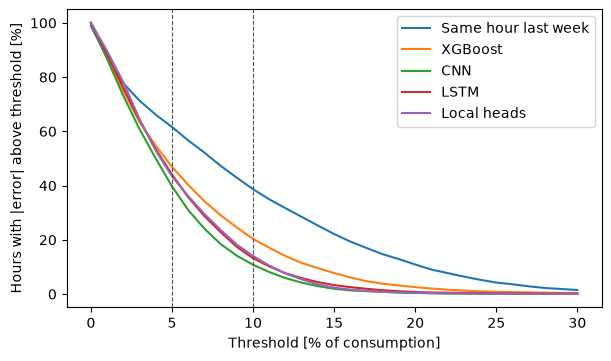

In [10]:
exceedance = pd.DataFrame({name: [100 * (rows["abs_pct"] > x).mean() for x in THRESHOLD_CURVE]
                           for name, rows in errors.groupby("model", observed=True)}, index=THRESHOLD_CURVE)
fig, ax = plt.subplots(figsize=(6, 3.5), layout="constrained")
exceedance.plot(ax=ax, color=test.colors(exceedance.columns))
for x in (TOLERANCE_PCT, LARGE_ERROR_PCT):
    ax.axvline(x, color="#52514e", linestyle="--", linewidth=0.8)
ax.set_xlabel("Threshold [% of consumption]")
ax.set_ylabel("Hours with |error| above threshold [%]")
ax.legend(title=None)
fig.savefig(FIGURES / "error_exceedance.pdf")

## Peak hours ##
Peak hours are the top 10 % of actual consumption in each area (the same hours for every model), mostly cold weekday
mornings and evenings. If errors were spread evenly, 10 % of the imbalance would fall in peak hours. A larger share means
the model is weakest when the retailer is most exposed.

In [11]:
def peak_kpis(rows: pd.DataFrame) -> pd.Series:
    peak, other = rows[rows["peak"]], rows[~rows["peak"]]
    return pd.Series({"peak_imbalance_mwh": peak["abs_error"].sum(),
                      "peak_share_of_imbalance_pct": 100 * peak["abs_error"].sum() / rows["abs_error"].sum(),
                      "peak_nmae": 100 * peak["abs_error"].sum() / peak["actual"].sum(),
                      "other_nmae": 100 * other["abs_error"].sum() / other["actual"].sum(),
                      "peak_large_error_hours_pct": 100 * (peak["abs_pct"] > LARGE_ERROR_PCT).mean(),
                      "other_large_error_hours_pct": 100 * (other["abs_pct"] > LARGE_ERROR_PCT).mean(),
                      "peak_cost_eur": peak["cost_eur"].sum(),
                      "peak_exposure_eur": peak["exposure_eur"].sum()})


peak = by_area(errors, peak_kpis)
peak["peak_imbalance_reduction_pct"] = reduction(peak, "peak_imbalance_mwh")
peak.xs("All", level="area").round(2)

,peak_imbalance_mwh,peak_share_of_imbalance_pct,peak_nmae,other_nmae,peak_large_error_hours_pct,other_large_error_hours_pct,peak_cost_eur,peak_exposure_eur,peak_imbalance_reduction_pct
model,,,,,,,,,
Same hour last week,822.35,15.84,11.75,8.60,50.29,37.36,4128.79,13699.77,0.00
XGBoost,364.19,10.39,5.20,6.18,13.69,21.05,1779.08,6760.91,55.71
CNN,376.95,13.98,5.39,4.57,12.07,10.65,1104.55,6704.49,54.16
LSTM,417.39,14.01,5.96,5.04,13.40,13.18,2128.58,7671.38,49.25
Local heads,492.44,15.90,7.04,5.13,18.92,13.50,909.10,8155.56,40.12


In [12]:
pd.concat({"Peak imbalance [MWh]": wide(peak, "peak_imbalance_mwh"),
           "Peak reduction vs baseline [%]": wide(peak, "peak_imbalance_reduction_pct").drop(columns=BASELINE),
           "Peak hours with large error [%]": wide(peak, "peak_large_error_hours_pct")}, axis=1).round(1)

Peak imbalance [MWh]                                    \
model           Same hour last week XGBoost    CNN   LSTM Local heads   
area                                                                    
NO1 Oslo                      381.2   126.4  137.9  159.2       237.8   
NO2 Stavanger                 164.3    74.6   95.3   84.6        69.5   
NO3 Trondheim                 102.5    65.0   24.5   66.7        39.7   
NO4 Tromsø                     56.6    22.4   17.1   22.5        31.6   
NO5 Bergen                     73.7    40.7   38.9   47.5        48.9   
FI Helsingfors                 44.1    35.2   63.3   36.9        64.9   
All                           822.4   364.2  377.0  417.4       492.4   

               Peak reduction vs baseline [%]                          \
model                                 XGBoost   CNN  LSTM Local heads   
area                                                                    
NO1 Oslo                                 66.8  63.8  58.2        37.6   
NO2 Stavanger                            54.6  42.0  48.5        57.7   
NO3 Trondheim                            36.6  76.1  34.9        61.3   
NO4 Tromsø                               60.5  69.7  60.3        44.2   
NO5 Bergen                               44.8  47.2  35.5        33.6   
FI Helsingfors                           20.2 -43.5  16.3       -47.1   
All                                      55.7  54.2  49.2        40.1   

               Peak hours with large error [%]                                  
model                      Same hour last week XGBoost   CNN  LSTM Local heads  
area                                                                            
NO1 Oslo                                  63.4     8.6   8.6   9.7        36.0  
NO2 Stavanger                             57.7    18.3  33.1  19.4         9.1  
NO3 Trondheim                             58.9    30.3   3.4  29.1         8.6  
NO4 Tromsø                                74.9    10.9   8.0   8.0        26.3  
NO5 Bergen                                45.7    14.3  11.4  14.3        23.4  
FI Helsingfors                             1.7     0.0   7.9   0.0        10.2  
All                                       50.3    13.7  12.1  13.4        18.9

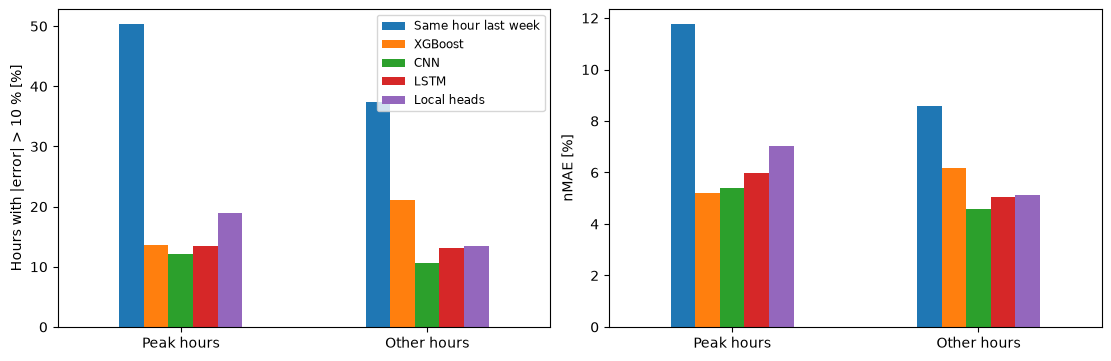

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
overall_peak = peak.xs("All", level="area")
overall_peak[["peak_large_error_hours_pct", "other_large_error_hours_pct"]].set_axis(["Peak hours", "Other hours"], axis=1).T.plot.bar(
    ax=axes[0], color=test.colors(NAMES), rot=0)
axes[0].set_ylabel(f"Hours with |error| > {LARGE_ERROR_PCT} % [%]")
overall_peak[["peak_nmae", "other_nmae"]].set_axis(["Peak hours", "Other hours"], axis=1).T.plot.bar(
    ax=axes[1], color=test.colors(NAMES), rot=0, legend=False)
axes[1].set_ylabel("nMAE [%]")
axes[0].legend(title=None, fontsize="small")
fig.savefig(FIGURES / "peak_vs_other_hours.pdf")

## Imbalance cost (eSett prices) ##
Realised cost and cost exposure in EUR over the test period, the saving against the baseline, and what drives the cost:

* **Against system**: the share of the imbalance (MWh) in hours where the retailer's imbalance had the same direction as
  the system's. Only these hours cost money under the single-price model.
* **Short / long**: underforecast and overforecast MWh.
* **Worst hours**: the share of the cost exposure that comes from the most expensive `TAIL_SHARE` of hours. A high share means
  that a few hours with price spikes decide the cost.

In [14]:
def cost_kpis(rows: pd.DataFrame) -> pd.Series:
    worst = rows["exposure_eur"].nlargest(max(1, int(TAIL_SHARE * len(rows))))
    return pd.Series({"realised_cost_eur": rows["cost_eur"].sum(),
                      "cost_exposure_eur": rows["exposure_eur"].sum(),
                      "realised_cost_per_mwh_eur": rows["cost_eur"].sum() / rows["abs_error"].sum(),
                      "against_system_pct": 100 * rows.loc[rows["against_system"], "abs_error"].sum() / rows["abs_error"].sum(),
                      "short_mwh": rows.loc[rows["error"] < 0, "abs_error"].sum(),
                      "long_mwh": rows.loc[rows["error"] > 0, "abs_error"].sum(),
                      "worst_hours_share_of_exposure_pct": 100 * worst.sum() / rows["exposure_eur"].sum()})


costs = by_area(errors, cost_kpis)
costs["realised_saving_eur"] = versus_baseline(costs, "realised_cost_eur") - costs["realised_cost_eur"]
costs["exposure_saving_eur"] = versus_baseline(costs, "cost_exposure_eur") - costs["cost_exposure_eur"]
costs.xs("All", level="area").round(1)

,realised_cost_eur,cost_exposure_eur,realised_cost_per_mwh_eur,against_system_pct,short_mwh,long_mwh,worst_hours_share_of_exposure_pct,realised_saving_eur,exposure_saving_eur
model,,,,,,,,,
Same hour last week,34895.7,76759.8,6.7,45.1,2417.9,2774.2,27.1,0.0,0.0
XGBoost,12167.0,50853.1,3.5,39.0,950.2,2554.1,22.0,22728.7,25906.7
CNN,4371.5,43747.1,1.6,35.5,1356.7,1340.7,23.3,30524.1,33012.7
LSTM,2958.9,48137.0,1.0,35.3,1445.4,1533.6,25.0,31936.8,28622.9
Local heads,-549.4,47898.9,-0.2,28.5,2498.3,599.2,24.8,35445.0,28861.0


In [15]:
pd.concat({"Realised cost [EUR]": wide(costs, "realised_cost_eur"),
           "Cost exposure [EUR]": wide(costs, "cost_exposure_eur")}, axis=1).round(0)

Realised cost [EUR]                                       \
model          Same hour last week  XGBoost     CNN    LSTM Local heads   
area                                                                      
NO1 Oslo                   19980.0   6226.0  2574.0  3200.0     -1923.0   
NO2 Stavanger               7702.0   3939.0  2028.0  1313.0      1452.0   
NO3 Trondheim               2267.0    700.0   643.0  -614.0     -1387.0   
NO4 Tromsø                  1089.0    449.0   383.0   202.0       143.0   
NO5 Bergen                  4517.0   1465.0  1221.0  -229.0       362.0   
FI Helsingfors              -659.0   -611.0 -2477.0  -914.0       804.0   
All                        34896.0  12167.0  4372.0  2959.0      -549.0   

               Cost exposure [EUR]                                         
model          Same hour last week  XGBoost      CNN     LSTM Local heads  
area                                                                       
NO1 Oslo                   35257.0  20027.0  15211.0  16385.0     19592.0  
NO2 Stavanger              14579.0  10220.0   7855.0   9150.0      7195.0  
NO3 Trondheim               8942.0   5161.0   3503.0   4668.0      3981.0  
NO4 Tromsø                  2987.0   1739.0   1587.0   1298.0      2110.0  
NO5 Bergen                  8742.0   4679.0   4194.0   5084.0      4849.0  
FI Helsingfors              6253.0   9029.0  11397.0  11552.0     10172.0  
All                        76760.0  50853.0  43747.0  48137.0     47899.0

The cost is dominated by a few price spikes, so the saving is uncertain. A 95 % interval of the saving against the baseline
(all areas), from resampling whole days like `paired_bootstrap`.

In [16]:
def bootstrap_saving(col: str, n_boot: int = 2000, seed: int = 0) -> pd.DataFrame:
    daily = errors.groupby(["model", "date"], observed=True)[col].sum().unstack("model")
    saving = daily[BASELINE].to_numpy()[:, None] - daily[NAMES[1:]].to_numpy()
    pick = np.random.default_rng(seed).integers(0, len(daily), (n_boot, len(daily)))
    boot = saving[pick].sum(axis=1)
    low, high = np.quantile(boot, [0.025, 0.975], axis=0)
    return pd.DataFrame({"saving_eur": saving.sum(axis=0), "ci_low": low, "ci_high": high,
                         "significant": (low > 0) | (high < 0)}, index=NAMES[1:])


pd.concat({"Realised cost": bootstrap_saving("cost_eur"), "Cost exposure": bootstrap_saving("exposure_eur")}).round(0)

saving_eur   ci_low  ci_high  significant
Realised cost XGBoost         22729.0   6253.0  41153.0         True
              CNN             30524.0  14332.0  47830.0         True
              LSTM            31937.0  15771.0  50066.0         True
              Local heads     35445.0  19837.0  52360.0         True
Cost exposure XGBoost         25907.0  13020.0  40772.0         True
              CNN             33013.0  20930.0  46692.0         True
              LSTM            28623.0  17085.0  41524.0         True
              Local heads     28861.0  16725.0  42441.0         True

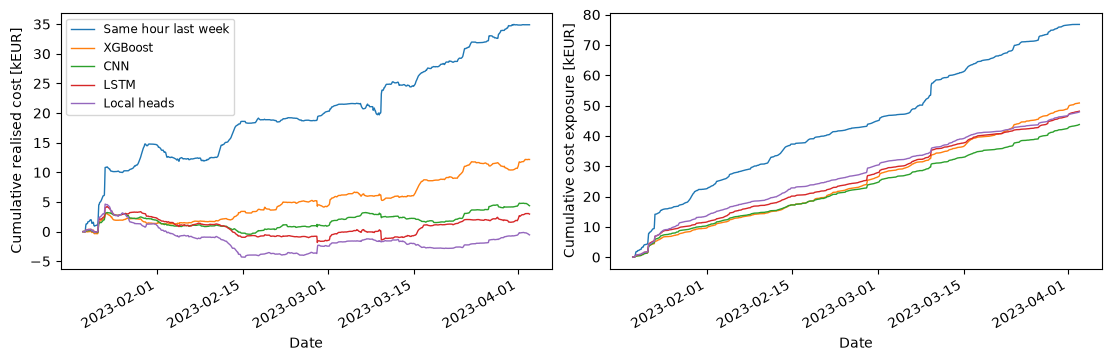

In [17]:
#Cumulative cost over the test period, all areas together
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharex=True, layout="constrained")
for ax, col, label in zip(axes, ["cost_eur", "exposure_eur"], ["Realised cost", "Cost exposure"]):
    hourly = errors.pivot_table(index="time", columns="model", values=col, aggfunc="sum", observed=True)[NAMES]
    (hourly.cumsum() / 1000).plot(ax=ax, color=test.colors(NAMES), linewidth=1, legend=ax is axes[0])
    ax.set_ylabel(f"Cumulative {label.lower()} [kEUR]")
    ax.set_xlabel("Date")
axes[0].legend(title=None, fontsize="small")
fig.savefig(FIGURES / "cumulative_imbalance_cost.pdf")

## Tail risk, days and weeks ##
The retailer notices bad days and weeks more than a good average. So the KPIs here are the 95th and 99th percentile and the
maximum of the hourly error, the worst day, the share of days whose imbalance is above `DAILY_LARGE_PCT` % of the day's
consumption, and how often the model beats the baseline on a single day or week (consistency).

In [18]:
def tail_kpis(rows: pd.DataFrame) -> pd.Series:
    return pd.Series({"p95_abs_pct": rows["abs_pct"].quantile(0.95),
                      "p99_abs_pct": rows["abs_pct"].quantile(0.99),
                      "max_abs_error_mw": rows["abs_error"].max()})


def per_period(frame: pd.DataFrame, keys: list[str], period: str) -> pd.DataFrame:
    #Imbalance per model, keys and period (date or week), and whether it is below the baseline's
    totals = frame.groupby(["model", *keys, period], observed=True)[["abs_error", "actual"]].sum()
    totals["pct"] = 100 * totals["abs_error"] / totals["actual"]
    baseline = totals.xs(BASELINE, level="model")["abs_error"]
    totals["beats_baseline"] = totals["abs_error"].to_numpy() < baseline.reindex(totals.index.droplevel("model")).to_numpy()
    totals["reduction_pct"] = 100 * (1 - totals["abs_error"].to_numpy() / baseline.reindex(totals.index.droplevel("model")).to_numpy())
    return totals


def day_kpis(days: pd.DataFrame) -> pd.Series:
    return pd.Series({"worst_day_imbalance_mwh": days["abs_error"].max(),
                      "bad_days_pct": 100 * (days["pct"] > DAILY_LARGE_PCT).mean(),
                      "days_better_than_baseline_pct": 100 * days["beats_baseline"].mean()})


def week_kpis(weeks: pd.DataFrame) -> pd.Series:
    return pd.Series({"weeks_better_than_baseline_pct": 100 * weeks["beats_baseline"].mean(),
                      "worst_week_reduction_pct": weeks["reduction_pct"].min()})


tails = by_area(errors, tail_kpis)
#Only whole days (23 hours on the DST day); the test period ends with a single hour of 3 Apr in Helsingfors
whole_days = errors[errors.groupby(["model", "area", "date"], observed=True)["actual"].transform("size") >= 23]
#Days: "All" is the portfolio, i.e. the imbalance of all areas summed per day
days = with_overall(per_period(whole_days, ["area"], "date").groupby(["model", "area"], observed=True).apply(day_kpis),
                    per_period(whole_days, [], "date").groupby("model", observed=True).apply(day_kpis))
#Weeks: "All" is over every area-week, so the worst week is the worst area in its worst week. Only whole weeks, as the
#test period starts on a Friday and ends on a Monday
area_weeks = per_period(whole_days[whole_days.groupby("week")["date"].transform("nunique") == 7], ["area"], "week")
weeks = with_overall(area_weeks.groupby(["model", "area"], observed=True).apply(week_kpis),
                     area_weeks.groupby("model", observed=True).apply(week_kpis))
pd.concat([tails, days, weeks], axis=1).xs("All", level="area").round(2)

,p95_abs_pct,p99_abs_pct,max_abs_error_mw,worst_day_imbalance_mwh,bad_days_pct,days_better_than_baseline_pct,weeks_better_than_baseline_pct,worst_week_reduction_pct
model,,,,,,,,
Same hour last week,24.30,32.27,4.96,159.30,76.71,0.00,0.00,0.00
XGBoost,16.79,23.96,3.75,97.51,65.75,71.23,71.67,-141.33
CNN,12.49,17.15,2.43,82.29,28.77,87.67,75.00,-222.49
LSTM,13.49,19.10,3.52,83.84,46.58,79.45,76.67,-207.72
Local heads,13.20,17.50,3.08,85.76,47.95,72.60,78.33,-265.43


In [19]:
pd.concat({"P99 |error| [%]": wide(tails, "p99_abs_pct"),
           f"Days with imbalance > {DAILY_LARGE_PCT} % [%]": wide(days, "bad_days_pct"),
           "Days better than baseline [%]": wide(days, "days_better_than_baseline_pct").drop(columns=BASELINE)},
          axis=1).round(1)

P99 |error| [%]                                  \
model          Same hour last week XGBoost   CNN  LSTM Local heads   
area                                                                 
NO1 Oslo                      34.3    23.8  17.0  18.5        17.8   
NO2 Stavanger                 35.2    29.9  18.3  22.5        20.9   
NO3 Trondheim                 28.2    21.2  18.2  17.3        15.4   
NO4 Tromsø                    27.9    17.6  15.2  17.2        17.9   
NO5 Bergen                    34.0    24.0  18.2  19.7        17.3   
FI Helsingfors                20.3    15.8  13.1  15.4        12.0   
All                           32.3    24.0  17.2  19.1        17.5   

               Days with imbalance > 5 % [%]                                  \
model                    Same hour last week XGBoost   CNN  LSTM Local heads   
area                                                                           
NO1 Oslo                                68.5    71.2  41.1  43.8        53.4   
NO2 Stavanger                           72.6    65.8  43.8  61.6        38.4   
NO3 Trondheim                           83.6    57.5  31.5  65.8        47.9   
NO4 Tromsø                              71.2    47.9  45.2  39.7        47.9   
NO5 Bergen                              84.9    47.9  39.7  60.3        57.5   
FI Helsingfors                           9.6     8.2  12.3   6.8         6.8   
All                                     76.7    65.8  28.8  46.6        47.9   

               Days better than baseline [%]                          
model                                XGBoost   CNN  LSTM Local heads  
area                                                                  
NO1 Oslo                                57.5  72.6  74.0        67.1  
NO2 Stavanger                           60.3  79.5  65.8        76.7  
NO3 Trondheim                           80.8  83.6  79.5        75.3  
NO4 Tromsø                              71.2  67.1  84.9        74.0  
NO5 Bergen                              79.5  84.9  69.9        76.7  
FI Helsingfors                          35.6  20.5  26.0        19.2  
All                                     71.2  87.7  79.5        72.6

In [20]:
#Imbalance reduction against the baseline per area and whole week [%]
weekly = area_weeks["reduction_pct"].drop(BASELINE, level="model")
weekly.unstack("week").rename(columns=lambda week: f"{week:%d %b}").round(0)

week                        23 Jan  30 Jan  06 Feb  13 Feb  20 Feb  27 Feb  \
model       area                                                             
XGBoost     NO1 Oslo          51.0    55.0    58.0    22.0   -54.0   -76.0   
            NO2 Stavanger     49.0    43.0    34.0     4.0   -57.0  -135.0   
            NO3 Trondheim     54.0    53.0    54.0    36.0    39.0    52.0   
            NO4 Tromsø        18.0    58.0    53.0   -40.0    60.0    66.0   
            NO5 Bergen        62.0    51.0    67.0    56.0    36.0     1.0   
            FI Helsingfors   -65.0    26.0    49.0    24.0  -141.0   -17.0   
CNN         NO1 Oslo          61.0    59.0    72.0    26.0     9.0    -2.0   
            NO2 Stavanger     37.0    38.0    61.0    56.0    24.0   -26.0   
            NO3 Trondheim     69.0    79.0    64.0    34.0    60.0    52.0   
            NO4 Tromsø        23.0    61.0    63.0   -64.0    55.0    68.0   
            NO5 Bergen        45.0    54.0    50.0    56.0    34.0    28.0   
            FI Helsingfors  -189.0   -21.0    25.0  -108.0  -222.0   -67.0   
LSTM        NO1 Oslo          62.0    55.0    65.0    54.0     6.0   -23.0   
            NO2 Stavanger     50.0    27.0    31.0    42.0    -0.0  -122.0   
            NO3 Trondheim     52.0    43.0    65.0    14.0    21.0    33.0   
            NO4 Tromsø        56.0    57.0    75.0    19.0    61.0    72.0   
            NO5 Bergen        50.0    21.0     0.0   -27.0   -32.0    52.0   
            FI Helsingfors  -208.0    22.0    30.0    13.0  -160.0   -49.0   
Local heads NO1 Oslo           9.0    37.0    40.0    30.0    -3.0    17.0   
            NO2 Stavanger     53.0    38.0    57.0    66.0    30.0   -65.0   
            NO3 Trondheim     43.0    62.0    48.0    13.0    37.0    11.0   
            NO4 Tromsø        41.0    41.0    48.0    41.0    33.0    63.0   
            NO5 Bergen        39.0    26.0    27.0     8.0    -9.0    29.0   
            FI Helsingfors  -265.0   -35.0    36.0   -79.0  -178.0   -16.0   

week                        06 Mar  13 Mar  20 Mar  27 Mar  
model       area                                            
XGBoost     NO1 Oslo          54.0    38.0    16.0    -1.0  
            NO2 Stavanger     61.0    27.0   -25.0    32.0  
            NO3 Trondheim     49.0    59.0     3.0    16.0  
            NO4 Tromsø        65.0    43.0   -57.0   -16.0  
            NO5 Bergen        65.0    59.0    11.0   -49.0  
            FI Helsingfors   -55.0   -61.0   -74.0   -87.0  
CNN         NO1 Oslo          71.0    71.0    53.0    27.0  
            NO2 Stavanger     62.0    67.0    53.0    37.0  
            NO3 Trondheim     73.0    76.0    -8.0    38.0  
            NO4 Tromsø        71.0    43.0    16.0   -45.0  
            NO5 Bergen        71.0    65.0    71.0   -18.0  
            FI Helsingfors   -85.0   -93.0   -95.0   -81.0  
LSTM        NO1 Oslo          64.0    59.0    68.0     0.0  
            NO2 Stavanger     51.0    52.0    66.0    28.0  
            NO3 Trondheim     62.0    77.0    44.0    19.0  
            NO4 Tromsø        66.0    39.0   -19.0     5.0  
            NO5 Bergen        69.0    59.0    75.0   -17.0  
            FI Helsingfors   -72.0   -88.0   -83.0  -145.0  
Local heads NO1 Oslo          57.0    44.0    63.0    48.0  
            NO2 Stavanger     61.0    67.0    52.0    45.0  
            NO3 Trondheim     75.0    65.0    61.0    31.0  
            NO4 Tromsø        37.0    51.0    32.0  -119.0  
            NO5 Bergen        66.0    68.0    79.0     2.0  
            FI Helsingfors   -16.0   -13.0   -42.0  -110.0

## Is the reduction significant? ##
`paired_bootstrap` of each model against the baseline, resampling whole days. This gives the imbalance reduction $\Delta I$
with a 95 % interval per area and for all areas.

In [21]:
all_areas = pd.Series("All", index=test.actual.index, name="Price area")
baseline_mae = pd.concat([test.per_group().loc[BASELINE, "mae"], pd.Series({"All": test.summary().loc[BASELINE, "mae"]})])
significance = {}
for name in NAMES[1:]:
    boot = pd.concat([paired_bootstrap(test.actual, test.forecasts[name], test.forecasts[BASELINE], info["date"], groups)
                      for groups in (test.groups, all_areas)])
    #A negative MAE difference is a positive reduction, so the interval is flipped
    significance[name] = pd.DataFrame({"reduction_pct": -100 * boot["mae_difference"] / baseline_mae,
                                       "ci_low": -100 * boot["ci_high"] / baseline_mae,
                                       "ci_high": -100 * boot["ci_low"] / baseline_mae,
                                       "significant": boot["significant"]}).reindex([*AREAS.values(), "All"])
significance = pd.concat(significance, names=["model", "area"])
significance.round(1)

reduction_pct  ci_low  ci_high  significant
model       area                                                       
XGBoost     NO1 Oslo                 35.2    17.8     53.3         True
            NO2 Stavanger            21.7     4.1     38.6         True
            NO3 Trondheim            44.3    30.4     57.7         True
            NO4 Tromsø               38.2    23.5     53.0         True
            NO5 Bergen               43.5    30.3     57.1         True
            FI Helsingfors          -16.4   -35.2      1.7        False
            All                      32.5    20.3     44.5         True
CNN         NO1 Oslo                 55.7    39.6     73.3         True
            NO2 Stavanger            48.5    33.6     63.5         True
            NO3 Trondheim            58.7    43.2     73.7         True
            NO4 Tromsø               42.3    25.7     59.0         True
            NO5 Bergen               53.7    40.1     67.6         True
            FI Helsingfors          -65.3   -85.0    -45.4         True
            All                      48.0    36.5     59.4         True
LSTM        NO1 Oslo                 52.7    36.5     69.9         True
            NO2 Stavanger            37.5    20.1     55.4         True
            NO3 Trondheim            46.8    33.7     60.3         True
            NO4 Tromsø               51.8    38.0     65.6         True
            NO5 Bergen               37.2    21.0     52.9         True
            FI Helsingfors          -42.6   -60.0    -24.8         True
            All                      42.6    30.8     55.0         True
Local heads NO1 Oslo                 40.5    23.9     58.1         True
            NO2 Stavanger            51.3    35.5     67.4         True
            NO3 Trondheim            49.6    35.0     64.5         True
            NO4 Tromsø               35.1    18.7     50.5         True
            NO5 Bergen               44.0    29.6     58.6         True
            FI Helsingfors          -39.0   -56.4    -20.3         True
            All                      40.3    28.2     52.7         True

## Imbalance per price area (figure) ##

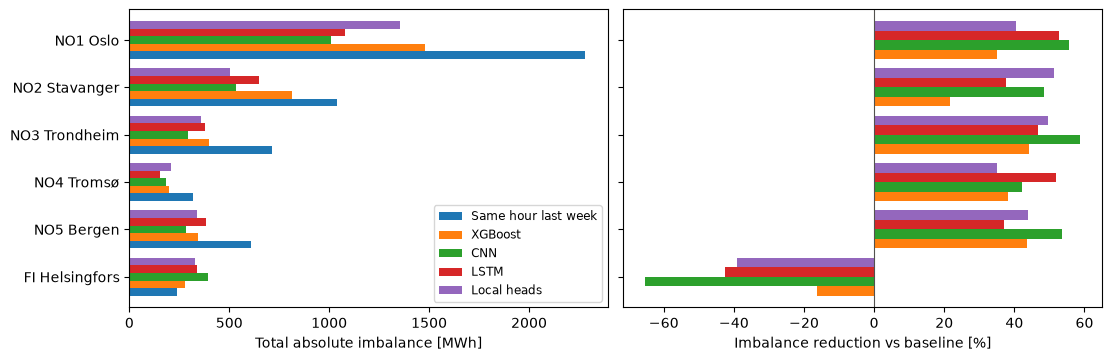

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True, layout="constrained")
areas = list(AREAS.values())[::-1]
wide(kpis, "imbalance_mwh").loc[areas].plot.barh(ax=axes[0], color=test.colors(NAMES), width=0.8)
axes[0].set_xlabel("Total absolute imbalance [MWh]")
axes[0].set_ylabel("")
axes[0].legend(title=None, fontsize="small")
models = NAMES[1:]
wide(kpis, "imbalance_reduction_pct").loc[areas, models].plot.barh(ax=axes[1], color=test.colors(models), width=0.8, legend=False)
axes[1].axvline(0, color="#52514e", linewidth=0.8)
axes[1].set_xlabel("Imbalance reduction vs baseline [%]")
fig.savefig(FIGURES / "imbalance_per_area.pdf")

## Summary (`tab:business`) ##
All KPIs for all areas together, for every model, and the table for the report: the baseline against the model with the
lowest total imbalance. Change is in the unit of the KPI (percentage points for KPIs in %). Change [%] is relative to the
baseline and is only given for KPIs that are not already percentages.

In [23]:
overall = pd.concat([kpis, peak, costs, tails, days, weeks], axis=1)
LABELS = {"imbalance_mwh": "Total abs. imbalance [MWh]",
          "imbalance_reduction_pct": "Imbalance reduction vs baseline [%]",
          "large_error_hours_pct": f"Hours with large error (> {LARGE_ERROR_PCT} %) [%]",
          "within_tolerance_pct": f"Hours within tolerance (±{TOLERANCE_PCT} %) [%]",
          "median_abs_error_mw": "Median abs. error [MW]",
          "peak_imbalance_mwh": "Peak-hour imbalance [MWh]",
          "peak_share_of_imbalance_pct": "Share of imbalance in peak hours [%]",
          "peak_large_error_hours_pct": "Peak hours with large error [%]",
          "realised_cost_eur": "Realised imbalance cost [EUR]",
          "cost_exposure_eur": "Imbalance cost exposure [EUR]",
          "peak_exposure_eur": "Cost exposure in peak hours [EUR]",
          "against_system_pct": "Imbalance against the system [%]",
          "p99_abs_pct": "99th percentile abs. error [%]",
          "worst_day_imbalance_mwh": "Worst day imbalance [MWh]",
          "bad_days_pct": f"Days with imbalance > {DAILY_LARGE_PCT} % [%]",
          "weeks_better_than_baseline_pct": "Area-weeks better than baseline [%]"}
overview = overall.xs("All", level="area")[list(LABELS)].T.rename(index=LABELS)[NAMES]
overview.round(2)

model,Same hour last week,XGBoost,CNN,LSTM,Local heads
Total abs. imbalance [MWh],5192.09,3504.30,2697.35,2979.01,3097.51
Imbalance reduction vs baseline [%],0.00,32.51,48.05,42.62,40.34
Hours with large error (> 10 %) [%],38.66,20.31,10.80,13.21,14.04
Hours within tolerance (±5 %) [%],38.40,53.07,60.28,55.94,56.61
Median abs. error [MW],0.29,0.19,0.17,0.20,0.19
Peak-hour imbalance [MWh],822.35,364.19,376.95,417.39,492.44
Share of imbalance in peak hours [%],15.84,10.39,13.98,14.01,15.90
Peak hours with large error [%],50.29,13.69,12.07,13.40,18.92
Realised imbalance cost [EUR],34895.66,12166.98,4371.52,2958.90,-549.38
Imbalance cost exposure [EUR],76759.85,50853.10,43747.10,48137.00,47898.87


In [24]:
best = overview.loc[LABELS["imbalance_mwh"]].drop(BASELINE).idxmin()
summary = overview[[BASELINE, best]].copy()
summary["Change"] = summary[best] - summary[BASELINE]
summary["Change [%]"] = (100 * summary["Change"] / summary[BASELINE].abs()).where(~summary.index.str.endswith("[%]"))
print(f"Best model by total imbalance: {best}")
summary.round(2)

Best model by total imbalance: CNN


model,Same hour last week,CNN,Change,Change [%]
Total abs. imbalance [MWh],5192.09,2697.35,-2494.74,-48.05
Imbalance reduction vs baseline [%],0.00,48.05,48.05,NaN
Hours with large error (> 10 %) [%],38.66,10.80,-27.86,NaN
Hours within tolerance (±5 %) [%],38.40,60.28,21.88,NaN
Median abs. error [MW],0.29,0.17,-0.12,-40.93
Peak-hour imbalance [MWh],822.35,376.95,-445.40,-54.16
Share of imbalance in peak hours [%],15.84,13.98,-1.86,NaN
Peak hours with large error [%],50.29,12.07,-38.21,NaN
Realised imbalance cost [EUR],34895.66,4371.52,-30524.14,-87.47
Imbalance cost exposure [EUR],76759.85,43747.10,-33012.75,-43.01


In [25]:
print(summary.to_latex(float_format="%.1f", na_rep="--"))

\begin{tabular}{lrrrr}
\toprule
model & Same hour last week & CNN & Change & Change [%] \\
\midrule
Total abs. imbalance [MWh] & 5192.1 & 2697.4 & -2494.7 & -48.0 \\
Imbalance reduction vs baseline [%] & 0.0 & 48.0 & 48.0 & -- \\
Hours with large error (> 10 %) [%] & 38.7 & 10.8 & -27.9 & -- \\
Hours within tolerance (±5 %) [%] & 38.4 & 60.3 & 21.9 & -- \\
Median abs. error [MW] & 0.3 & 0.2 & -0.1 & -40.9 \\
Peak-hour imbalance [MWh] & 822.4 & 377.0 & -445.4 & -54.2 \\
Share of imbalance in peak hours [%] & 15.8 & 14.0 & -1.9 & -- \\
Peak hours with large error [%] & 50.3 & 12.1 & -38.2 & -- \\
Realised imbalance cost [EUR] & 34895.7 & 4371.5 & -30524.1 & -87.5 \\
Imbalance cost exposure [EUR] & 76759.8 & 43747.1 & -33012.7 & -43.0 \\
Cost exposure in peak hours [EUR] & 13699.8 & 6704.5 & -6995.3 & -51.1 \\
Imbalance against the system [%] & 45.1 & 35.5 & -9.5 & -- \\
99th percentile abs. error [%] & 32.3 & 17.2 & -15.1 & -- \\
Worst day imbalance [MWh] & 159.3 & 82.3 & -77.0 & -48.3 \

In [26]:
save_tables(RESULTS / "business_kpis.json", summary=summary, overview=overview,
            per_area=overall.reset_index(), significance=significance.reset_index(),
            spread_by_peak=spread_by_peak)

## Conclusion ##
Numbers from the run with the settings above (large error > 10 %, tolerance ±5 %, peak = top 10 %); 74 test days, 6 areas.

* **Best model: the CNN.** Total imbalance 2,697 MWh against 5,192 MWh for the baseline, a reduction of 48 %
  (95 % interval 37 - 59 %). It is also best on almost every risk KPI: hours with a large error 38.7 % → 10.8 %, hours within
  ±5 % 38.4 % → 60.3 %, 99th percentile error 32 % → 17 %, worst day 159 → 82 MWh, and days with more than 5 % imbalance 76 % → 28 %.
  It beats the baseline on 88 % of portfolio days and on 75 % of area-weeks.
* **Peak hours.** The baseline is weakest there: 50 % of its peak hours have a large error, and 15.8 % of its imbalance falls
  in the top 10 % of hours. Every model about halves the peak imbalance (−40 to −56 %). XGBoost is best in peak hours (364 MWh,
  10.4 % of its imbalance) although it is the weakest model overall.
* **Peak hours are not more expensive per MWh.** The mean |imbalance − spot| spread in peak hours is about the same as in
  other hours (ratio 0.74 - 1.45; only Bergen is clearly higher). Peak errors cost more because they are larger, not because
  the price is higher. Helsingfors has by far the most volatile spread (up to 2,865 EUR/MWh).
* **Cost.** Cost exposure falls from 76.8 to 43.7 kEUR (−43 %) and the realised cost from 34.9 to 4.4 kEUR. All savings
  are significant, but the intervals are wide because a few price spikes dominate (the worst 1 % of hours carry about 25 % of the
  exposure). The realised cost depends on the direction of the system imbalance: the local heads come out at −0.5 kEUR because they
  underforecast (2,498 MWh short) while the system was mostly long. That is luck, not skill, so the **cost exposure is the more robust
  cost KPI** for comparing models.
* **Helsingfors** is the exception. Every model is worse than the baseline there (the CNN by 65 %), and the baseline is within ±5 %
  in 90 % of hours. A per-area choice (the CNN for the NO areas, the baseline for FI) looks attractive, but it should be chosen on
  the validation windows, not on these test numbers.
* **Weak weeks.** The worst area-weeks are Helsingfors and NO1/NO2 in late February. These are candidates for monitoring
  alerts (rolling bias, `\cref{sec:monitoring}`).
